# CT-351 Knowledge Representation & Reasoning CCP
## Student Scholarship Eligibility System

This project includes: frames with slots/facets/defaults, a semantic network (IS-A / HAS-A / PART-OF / DEPENDS-ON), FOL and DL representations, Horn clause rules, forward chaining, backward chaining, and sample evaluations.

**Project assumptions:** CGPA ≥ 3.00, attendance ≥ 75%, and monthly family income ≤ PKR 100,000. These are illustrative criteria for the course project, not official university scholarship rules. `None` means information is missing; it is never treated as zero.

**Input validation:** Before inference, the notebook checks that CGPA is within 0–4, attendance is within 0–100, and monthly income is non-negative. Missing values remain UNKNOWN and can lead to PENDING; invalid values are rejected as INVALID INPUT.


In [21]:
import math

# ============================================================
# CT-351: KNOWLEDGE REPRESENTATION & REASONING (CCP)
# Project: Student Scholarship Eligibility System
# This is a small, explainable course-project rule engine.
# ============================================================

# ------------------------------------------------------------
# 1. DOMAIN POLICY AND SAMPLE KNOWLEDGE BASE
# ------------------------------------------------------------
CGPA_MINIMUM = 3.00
ATTENDANCE_MINIMUM = 75.0
MONTHLY_INCOME_MAXIMUM = 100000.0  # PKR

students = {
    "Ali": {
        "cgpa": 3.65,
        "attendance": 90.0,
        "monthly_income": 60000.0
    },
    "Sara": {
        "cgpa": 3.20,
        "attendance": 80.0,
        "monthly_income": 120000.0
    },
    "Ahmed": {
        "cgpa": 2.70,
        "attendance": 85.0,
        "monthly_income": 50000.0
    },
    "Ayesha": {
        "cgpa": 3.40,
        "attendance": 70.0,
        "monthly_income": 70000.0
    },
    "Usman": {
        "cgpa": 3.50,
        "attendance": None,  # None means unknown/missing, not zero.
        "monthly_income": 80000.0
    },
    # Boundary test: all conditions use inclusive limits.
    "Zainab": {
        "cgpa": 3.00,
        "attendance": 75.0,
        "monthly_income": -100.0
    }
}
print("CT-351 KNOWLEDGE REPRESENTATION & REASONING CCP")
print("Student Scholarship Eligibility System")
print("Project thresholds: CGPA >= {:.2f}, attendance >= {:.1f}%, "
      "monthly family income <= PKR {:,.0f}".format(
          CGPA_MINIMUM, ATTENDANCE_MINIMUM, MONTHLY_INCOME_MAXIMUM
      ))


CT-351 KNOWLEDGE REPRESENTATION & REASONING CCP
Student Scholarship Eligibility System
Project thresholds: CGPA >= 3.00, attendance >= 75.0%, monthly family income <= PKR 100,000


In [12]:
# ------------------------------------------------------------
# 2. FRAMES: CLASSES, SLOTS, FACETS, AND DEFAULTS
# ------------------------------------------------------------
# Facets describe slot type/range/constraint. None indicates
# that a value has not been supplied; it is not treated as zero.

frames = {
    "Person": {
        "slots": {
            "name": {
                "type": "String",
                "cardinality": "exactly 1",
                "default": "Unknown",
                "constraint": "Must not be empty"
            }
        }
    },
    "Student": {
        "is_a": "Person",
        "slots": {
            "cgpa": {
                "type": "Float",
                "cardinality": "0 or 1",
                "default": None,
                "constraint": "0.00 to 4.00"
            },
            "attendance": {
                "type": "Float percentage",
                "cardinality": "0 or 1",
                "default": None,
                "constraint": "0 to 100"
            },
            "monthly_income": {
                "type": "Float in PKR",
                "cardinality": "0 or 1",
                "default": None,
                "constraint": "Must be non-negative"
            }
        }
    },
    "ScholarshipApplication": {
        "slots": {
            "applicant": {
                "type": "Student",
                "cardinality": "exactly 1",
                "default": None,
                "constraint": "Must refer to a student"
            },
            "cgpa_status": {
                "type": "PASS / FAIL / UNKNOWN",
                "cardinality": "exactly 1 after evaluation",
                "default": "UNKNOWN",
                "constraint": "Computed from CGPA"
            },
            "attendance_status": {
                "type": "PASS / FAIL / UNKNOWN",
                "cardinality": "exactly 1 after evaluation",
                "default": "UNKNOWN",
                "constraint": "Computed from attendance"
            },
            "income_status": {
                "type": "PASS / FAIL / UNKNOWN",
                "cardinality": "exactly 1 after evaluation",
                "default": "UNKNOWN",
                "constraint": "Computed from monthly income"
            },
            "decision": {
                "type": "ELIGIBLE / NOT ELIGIBLE / PENDING",
                "cardinality": "exactly 1 after evaluation",
                "default": "PENDING",
                "constraint": "Derived by the inference engine"
            }
        }
    }
}


def display_frames():
    print("\n" + "=" * 72)
    print("FRAMES: SLOTS, FACETS, AND DEFAULT VALUES")
    print("=" * 72)
    for frame_name, frame_info in frames.items():
        print("\nFrame:", frame_name)
        if "is_a" in frame_info:
            print("  IS-A:", frame_info["is_a"])
        for slot_name, facets in frame_info["slots"].items():
            print("  Slot:", slot_name)
            for facet_name, facet_value in facets.items():
                print("    {:12s}: {}".format(facet_name, facet_value))
display_frames()



FRAMES: SLOTS, FACETS, AND DEFAULT VALUES

Frame: Person
  Slot: name
    type        : String
    cardinality : exactly 1
    default     : Unknown
    constraint  : Must not be empty

Frame: Student
  IS-A: Person
  Slot: cgpa
    type        : Float
    cardinality : 0 or 1
    default     : None
    constraint  : 0.00 to 4.00
  Slot: attendance
    type        : Float percentage
    cardinality : 0 or 1
    default     : None
    constraint  : 0 to 100
  Slot: monthly_income
    type        : Float in PKR
    cardinality : 0 or 1
    default     : None
    constraint  : Must be non-negative

Frame: ScholarshipApplication
  Slot: applicant
    type        : Student
    cardinality : exactly 1
    default     : None
    constraint  : Must refer to a student
  Slot: cgpa_status
    type        : PASS / FAIL / UNKNOWN
    cardinality : exactly 1 after evaluation
    default     : UNKNOWN
    constraint  : Computed from CGPA
  Slot: attendance_status
    type        : PASS / FAIL / UNK


SEMANTIC NETWORK RELATIONSHIPS
Student --IS-A--> Person
Student --HAS-A--> AcademicRecord
Student --HAS-A--> FinancialRecord
Student --HAS-A--> StudentProfile
AcademicRecord --PART-OF--> StudentProfile
FinancialRecord --PART-OF--> StudentProfile
ScholarshipApplication --HAS-A--> Student
ScholarshipApplication --HAS-A--> EligibilityDecision
EligibilityDecision --DEPENDS-ON--> CGPARequirement
EligibilityDecision --DEPENDS-ON--> AttendanceRequirement
EligibilityDecision --DEPENDS-ON--> IncomeRequirement


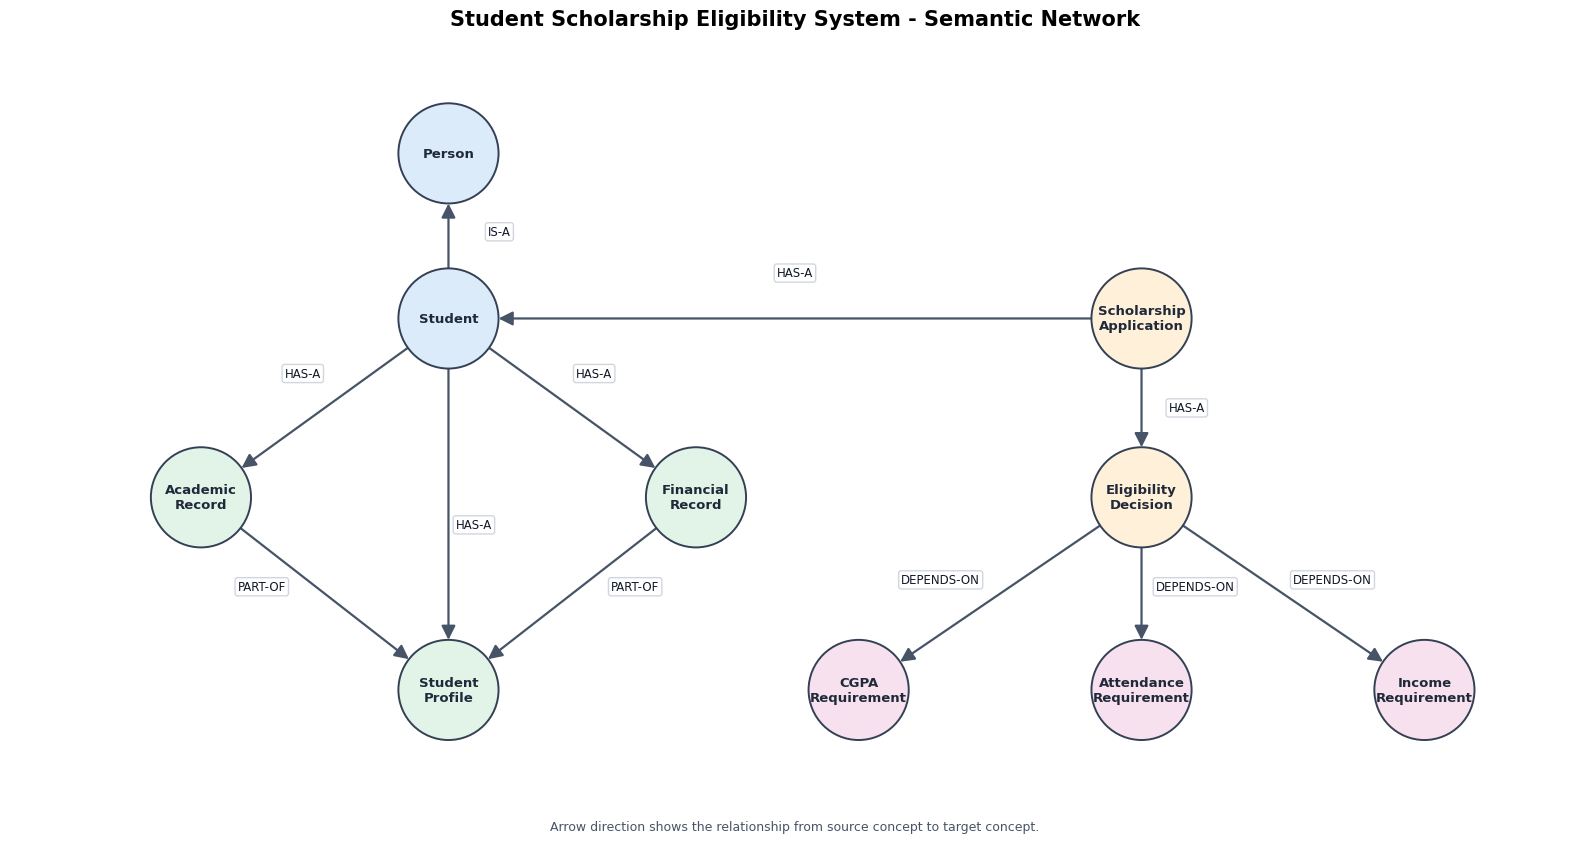

In [13]:
# ------------------------------------------------------------
# 3. SEMANTIC NETWORK
# ------------------------------------------------------------
# Relations include IS-A, HAS-A, PART-OF, and DEPENDS-ON.

semantic_network = [
    ("Student", "IS-A", "Person"),
    ("Student", "HAS-A", "AcademicRecord"),
    ("Student", "HAS-A", "FinancialRecord"),
    ("Student", "HAS-A", "StudentProfile"),
    ("AcademicRecord", "PART-OF", "StudentProfile"),
    ("FinancialRecord", "PART-OF", "StudentProfile"),
    ("ScholarshipApplication", "HAS-A", "Student"),
    ("ScholarshipApplication", "HAS-A", "EligibilityDecision"),
    ("EligibilityDecision", "DEPENDS-ON", "CGPARequirement"),
    ("EligibilityDecision", "DEPENDS-ON", "AttendanceRequirement"),
    ("EligibilityDecision", "DEPENDS-ON", "IncomeRequirement")
]


def display_semantic_network():
    """Print and draw a readable, fixed-layout semantic network."""
    print("\n" + "=" * 72)
    print("SEMANTIC NETWORK RELATIONSHIPS")
    print("=" * 72)
    for source, relation, target in semantic_network:
        print("{} --{}--> {}".format(source, relation, target))

    # Fixed positions avoid the overlapping labels that can happen with
    # an automatically generated spring layout.
    try:
        import networkx as nx
        import matplotlib.pyplot as plt

        graph = nx.DiGraph()
        for source, relation, target in semantic_network:
            graph.add_edge(source, target, label=relation)

        positions = {
            "Person": (0.0, 3.25),
            "Student": (0.0, 2.05),
            "AcademicRecord": (-1.75, 0.75),
            "FinancialRecord": (1.75, 0.75),
            "StudentProfile": (0.0, -0.65),
            "ScholarshipApplication": (4.9, 2.05),
            "EligibilityDecision": (4.9, 0.75),
            "CGPARequirement": (2.9, -0.65),
            "AttendanceRequirement": (4.9, -0.65),
            "IncomeRequirement": (6.9, -0.65),
        }

        labels = {
            "Person": "Person",
            "Student": "Student",
            "AcademicRecord": "Academic\nRecord",
            "FinancialRecord": "Financial\nRecord",
            "StudentProfile": "Student\nProfile",
            "ScholarshipApplication": "Scholarship\nApplication",
            "EligibilityDecision": "Eligibility\nDecision",
            "CGPARequirement": "CGPA\nRequirement",
            "AttendanceRequirement": "Attendance\nRequirement",
            "IncomeRequirement": "Income\nRequirement",
        }

        node_colors = []
        for node in graph.nodes():
            if node in ("Person", "Student"):
                node_colors.append("#DCEBFA")
            elif node in ("AcademicRecord", "FinancialRecord", "StudentProfile"):
                node_colors.append("#E2F3E8")
            elif node in ("ScholarshipApplication", "EligibilityDecision"):
                node_colors.append("#FFF0D9")
            else:
                node_colors.append("#F7E1EE")

        fig, ax = plt.subplots(figsize=(16, 8.5))
        nx.draw_networkx_nodes(
            graph, positions, node_size=5200, node_color=node_colors,
            edgecolors="#344054", linewidths=1.4, ax=ax
        )
        nx.draw_networkx_labels(
            graph, positions, labels=labels, font_size=9.5,
            font_weight="bold", font_color="#202939", ax=ax
        )
        nx.draw_networkx_edges(
            graph, positions, arrows=True, arrowstyle="-|>", arrowsize=21,
            width=1.6, edge_color="#475467", node_size=5200,
            connectionstyle="arc3,rad=0.0", ax=ax
        )

        # Place relation labels manually so they remain readable.
        relation_labels = [
            (0.36, 2.68, "IS-A"),
            (-1.03, 1.65, "HAS-A"),
            (1.03, 1.65, "HAS-A"),
            (0.18, 0.55, "HAS-A"),
            (-1.32, 0.10, "PART-OF"),
            (1.32, 0.10, "PART-OF"),
            (2.45, 2.38, "HAS-A"),
            (5.22, 1.40, "HAS-A"),
            (3.48, 0.15, "DEPENDS-ON"),
            (5.28, 0.10, "DEPENDS-ON"),
            (6.25, 0.15, "DEPENDS-ON"),
        ]
        for x, y, label in relation_labels:
            ax.text(
                x, y, label, ha="center", va="center", fontsize=8.5,
                color="#101828",
                bbox=dict(boxstyle="round,pad=0.22", fc="white",
                          ec="#D0D5DD", alpha=0.97)
            )

        ax.set_title(
            "Student Scholarship Eligibility System - Semantic Network",
            fontsize=15, fontweight="bold", pad=18
        )
        ax.text(
            0.5, -0.04,
            "Arrow direction shows the relationship from source concept to target concept.",
            transform=ax.transAxes, ha="center", fontsize=9, color="#475467"
        )
        ax.set_xlim(-3.1, 8.0)
        ax.set_ylim(-1.45, 4.0)
        ax.axis("off")
        plt.tight_layout()
        plt.show()

    except ImportError:
        print("Graph drawing libraries are unavailable; the relationships above are still shown.")

display_semantic_network()


In [14]:
# ------------------------------------------------------------
# 4. FORMAL LOGIC DEFINITIONS (FOL AND DESCRIPTION LOGIC)
# ------------------------------------------------------------

def display_formal_logic():
    print("\n" + "=" * 72)
    print("FIRST-ORDER LOGIC (FOL)")
    print("=" * 72)
    print("Predicates:")
    print("  Student(x): x is a student")
    print("  HasCGPA(x): CGPA value is available for x")
    print("  HasAttendance(x): attendance value is available for x")
    print("  HasIncome(x): monthly family income is available for x")
    print("  Eligible(x): x satisfies all three scholarship conditions")
    print("  NotEligible(x): at least one known condition fails")
    print()
    print("Numeric functions:")
    print("  CGPA(x): CGPA value of x (real number from 0 to 4)")
    print("  Attendance(x): attendance percentage of x (0 to 100)")
    print("  FamilyIncome(x): monthly family income of x in PKR")
    print()
    print("1. Eligibility definition (all three values must be known):")
    print("  forall x: [Student(x) AND HasCGPA(x) AND")
    print("      HasAttendance(x) AND HasIncome(x) AND")
    print("      CGPA(x) >= 3.00 AND Attendance(x) >= 75 AND")
    print("      FamilyIncome(x) <= 100000] -> Eligible(x)")
    print()
    print("2. Rejection rule (any one known failed condition is sufficient):")
    print("  forall x: [Student(x) AND (")
    print("      (HasCGPA(x) AND CGPA(x) < 3.00) OR")
    print("      (HasAttendance(x) AND Attendance(x) < 75) OR")
    print("      (HasIncome(x) AND FamilyIncome(x) > 100000))]")
    print("      -> NotEligible(x)")
    print()
    print("3. Eligible and not-eligible are mutually exclusive:")
    print("  forall x: NOT (Eligible(x) AND NotEligible(x))")
    print()
    print("4. Missing information:")
    print("  If no known condition fails but any required value is missing,")
    print("  neither Eligible(x) nor NotEligible(x) is derived; status is PENDING.")
    print()
    print("The numeric functions are only evaluated when their corresponding")
    print("Has... predicate is true. Invalid numeric ranges are rejected before")
    print("facts are created by the Python implementation.")

    print("\n" + "=" * 72)
    print("DESCRIPTION LOGIC (DL) - CONCEPTUAL AXIOMS")
    print("=" * 72)
    dl_axioms = [
        "Student SubClassOf Person",
        "ScholarshipApplicant SubClassOf Student",
        "EligibleStudent EquivalentTo Student AND",
        "  hasCGPA some decimal[>= 3.00] AND",
        "  hasAttendance some decimal[>= 75] AND",
        "  hasMonthlyFamilyIncome some decimal[<= 100000]",
        "NotEligibleStudent EquivalentTo Student AND (",
        "  hasCGPA some decimal[< 3.00] OR",
        "  hasAttendance some decimal[< 75] OR",
        "  hasMonthlyFamilyIncome some decimal[> 100000])",
        "EligibleStudent DisjointWith NotEligibleStudent",
        "hasCGPA: domain Student, range decimal[0.00, 4.00]",
        "hasAttendance: domain Student, range decimal[0, 100]",
        "hasMonthlyFamilyIncome: domain Student, range decimal[>= 0]"
    ]
    for axiom in dl_axioms:
        print("  " + axiom)
    print("\nThe DL axioms document the ontology; the Python chaining engine below")
    print("does not call a separate OWL/DL reasoner.")

display_formal_logic()



FIRST-ORDER LOGIC (FOL)
Predicates:
  Student(x): x is a student
  HasCGPA(x): CGPA value is available for x
  HasAttendance(x): attendance value is available for x
  HasIncome(x): monthly family income is available for x
  Eligible(x): x satisfies all three scholarship conditions
  NotEligible(x): at least one known condition fails

Numeric functions:
  CGPA(x): CGPA value of x (real number from 0 to 4)
  Attendance(x): attendance percentage of x (0 to 100)
  FamilyIncome(x): monthly family income of x in PKR

1. Eligibility definition (all three values must be known):
  forall x: [Student(x) AND HasCGPA(x) AND
      HasAttendance(x) AND HasIncome(x) AND
      CGPA(x) >= 3.00 AND Attendance(x) >= 75 AND
      FamilyIncome(x) <= 100000] -> Eligible(x)

2. Rejection rule (any one known failed condition is sufficient):
  forall x: [Student(x) AND (
      (HasCGPA(x) AND CGPA(x) < 3.00) OR
      (HasAttendance(x) AND Attendance(x) < 75) OR
      (HasIncome(x) AND FamilyIncome(x) > 100000

In [15]:
# ------------------------------------------------------------
# 5. NUMERIC OBSERVATIONS -> VALIDATION -> INITIAL LOGICAL FACTS
# ------------------------------------------------------------
# Numeric comparisons are evaluated once and represented as facts.
# Missing values are allowed; invalid values are rejected before inference.

def validate_student_data(data):
    """Return a list of input errors; an empty list means valid input."""
    errors = []
    if not isinstance(data, dict):
        return ["Student record must be a dictionary."]

    limits = {
        "cgpa": (0.0, 4.0, "CGPA must be between 0.00 and 4.00."),
        "attendance": (0.0, 100.0, "Attendance must be between 0 and 100."),
        "monthly_income": (0.0, None, "Monthly income must be non-negative.")
    }

    for field, (minimum, maximum, message) in limits.items():
        value = data.get(field)
        if value is None:
            continue  # Missing information is handled as UNKNOWN/PENDING.
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            errors.append("{} must be a numeric value or None.".format(field))
            continue
        if not math.isfinite(float(value)):
            errors.append("{} must be a finite numeric value.".format(field))
            continue
        if value < minimum or (maximum is not None and value > maximum):
            errors.append(message)

    return errors


def make_initial_facts(name, data):
    errors = validate_student_data(data)
    if errors:
        raise ValueError("Invalid student data: " + " ".join(errors))

    facts = {"STUDENT({})".format(name)}
    raw_checks = {}

    cgpa = data.get("cgpa")
    attendance = data.get("attendance")
    income = data.get("monthly_income")

    # Keep raw input records visible as facts for the trace/report.
    if cgpa is not None:
        facts.add("CGPA_RECORDED({})".format(name))
        if cgpa >= CGPA_MINIMUM:
            facts.add("CGPA_MEETS_MINIMUM({})".format(name))
            raw_checks["cgpa"] = "PASS"
        else:
            facts.add("CGPA_BELOW_MINIMUM({})".format(name))
            raw_checks["cgpa"] = "FAIL"
    else:
        raw_checks["cgpa"] = "UNKNOWN"

    if attendance is not None:
        facts.add("ATTENDANCE_RECORDED({})".format(name))
        if attendance >= ATTENDANCE_MINIMUM:
            facts.add("ATTENDANCE_MEETS_MINIMUM({})".format(name))
            raw_checks["attendance"] = "PASS"
        else:
            facts.add("ATTENDANCE_BELOW_MINIMUM({})".format(name))
            raw_checks["attendance"] = "FAIL"
    else:
        raw_checks["attendance"] = "UNKNOWN"

    if income is not None:
        facts.add("INCOME_RECORDED({})".format(name))
        if income <= MONTHLY_INCOME_MAXIMUM:
            facts.add("INCOME_WITHIN_LIMIT({})".format(name))
            raw_checks["monthly_income"] = "PASS"
        else:
            facts.add("INCOME_ABOVE_LIMIT({})".format(name))
            raw_checks["monthly_income"] = "FAIL"
    else:
        raw_checks["monthly_income"] = "UNKNOWN"

    return facts, raw_checks


In [16]:
# ------------------------------------------------------------
# 6. HORN CLAUSE KNOWLEDGE BASE
# ------------------------------------------------------------
# Rule format: (head, body, human-readable explanation)
# A rule with head H and body B1,...,Bn means:
# B1 AND ... AND Bn -> H


def make_rules_for_student(name):
    cgpa_ok = "CGPA_OK({})".format(name)
    cgpa_fail = "CGPA_FAILED({})".format(name)
    attendance_ok = "ATTENDANCE_OK({})".format(name)
    attendance_fail = "ATTENDANCE_FAILED({})".format(name)
    income_ok = "INCOME_OK({})".format(name)
    income_fail = "INCOME_FAILED({})".format(name)
    eligible = "ELIGIBLE({})".format(name)
    not_eligible = "NOT_ELIGIBLE({})".format(name)

    return [
        (cgpa_ok, ["CGPA_MEETS_MINIMUM({})".format(name)],
         "CGPA is at least the required minimum."),
        (cgpa_fail, ["CGPA_BELOW_MINIMUM({})".format(name)],
         "CGPA is below the required minimum."),
        (attendance_ok, ["ATTENDANCE_MEETS_MINIMUM({})".format(name)],
         "Attendance is at least the required minimum."),
        (attendance_fail, ["ATTENDANCE_BELOW_MINIMUM({})".format(name)],
         "Attendance is below the required minimum."),
        (income_ok, ["INCOME_WITHIN_LIMIT({})".format(name)],
         "Family income does not exceed the limit."),
        (income_fail, ["INCOME_ABOVE_LIMIT({})".format(name)],
         "Family income exceeds the limit."),
        (eligible, [cgpa_ok, attendance_ok, income_ok],
         "All three eligibility criteria have been proved."),
        (not_eligible, [cgpa_fail],
         "A failed CGPA condition is sufficient for rejection."),
        (not_eligible, [attendance_fail],
         "A failed attendance condition is sufficient for rejection."),
        (not_eligible, [income_fail],
         "An income above the limit is sufficient for rejection.")
    ]


def display_generic_horn_clauses():
    print("\n" + "=" * 72)
    print("HORN CLAUSE KNOWLEDGE BASE (GENERAL RULE SCHEMAS)")
    print("=" * 72)
    generic_rules = [
        "CGPA_OK(x) :- CGPA_MEETS_MINIMUM(x).",
        "CGPA_FAILED(x) :- CGPA_BELOW_MINIMUM(x).",
        "ATTENDANCE_OK(x) :- ATTENDANCE_MEETS_MINIMUM(x).",
        "ATTENDANCE_FAILED(x) :- ATTENDANCE_BELOW_MINIMUM(x).",
        "INCOME_OK(x) :- INCOME_WITHIN_LIMIT(x).",
        "INCOME_FAILED(x) :- INCOME_ABOVE_LIMIT(x).",
        "ELIGIBLE(x) :- CGPA_OK(x), ATTENDANCE_OK(x), INCOME_OK(x).",
        "NOT_ELIGIBLE(x) :- CGPA_FAILED(x).",
        "NOT_ELIGIBLE(x) :- ATTENDANCE_FAILED(x).",
        "NOT_ELIGIBLE(x) :- INCOME_FAILED(x)."
    ]
    for rule in generic_rules:
        print("  " + rule)
    print("\nFor execution, x is instantiated with each student name.")

display_generic_horn_clauses()


HORN CLAUSE KNOWLEDGE BASE (GENERAL RULE SCHEMAS)
  CGPA_OK(x) :- CGPA_MEETS_MINIMUM(x).
  CGPA_FAILED(x) :- CGPA_BELOW_MINIMUM(x).
  ATTENDANCE_OK(x) :- ATTENDANCE_MEETS_MINIMUM(x).
  ATTENDANCE_FAILED(x) :- ATTENDANCE_BELOW_MINIMUM(x).
  INCOME_OK(x) :- INCOME_WITHIN_LIMIT(x).
  INCOME_FAILED(x) :- INCOME_ABOVE_LIMIT(x).
  ELIGIBLE(x) :- CGPA_OK(x), ATTENDANCE_OK(x), INCOME_OK(x).
  NOT_ELIGIBLE(x) :- CGPA_FAILED(x).
  NOT_ELIGIBLE(x) :- ATTENDANCE_FAILED(x).
  NOT_ELIGIBLE(x) :- INCOME_FAILED(x).

For execution, x is instantiated with each student name.


In [17]:
# ------------------------------------------------------------
# 7. FORWARD CHAINING (DATA-DRIVEN INFERENCE)
# ------------------------------------------------------------


def forward_chaining(initial_facts, rules):
    facts = set(initial_facts)
    trace = []
    changed = True

    while changed:
        changed = False
        for head, body, explanation in rules:
            if all(condition in facts for condition in body) and head not in facts:
                facts.add(head)
                trace.append({
                    "rule": "{} :- {}".format(head, ", ".join(body)),
                    "conclusion": head,
                    "explanation": explanation
                })
                changed = True

    return facts, trace

In [18]:
# ------------------------------------------------------------
# 8. BACKWARD CHAINING (GOAL-DRIVEN INFERENCE)
# ------------------------------------------------------------


def backward_chaining(goal, facts, rules, trace, path=None, depth=0):
    if path is None:
        path = set()

    indent = "  " * depth
    trace.append(indent + "Goal: prove " + goal)

    if goal in facts:
        trace.append(indent + "SUCCESS: " + goal + " is a known fact.")
        return True

    if goal in path:
        trace.append(indent + "FAIL: loop detected while proving " + goal)
        return False

    matching_rules = [rule for rule in rules if rule[0] == goal]
    if not matching_rules:
        trace.append(indent + "FAIL: no known fact or rule can prove " + goal)
        return False

    next_path = set(path)
    next_path.add(goal)

    for head, body, explanation in matching_rules:
        trace.append(indent + "Try rule: {} :- {}".format(head, ", ".join(body)))
        trace.append(indent + "Reason: " + explanation)

        all_conditions_proved = True
        for condition in body:
            if not backward_chaining(
                condition, facts, rules, trace,
                path=next_path, depth=depth + 1
            ):
                all_conditions_proved = False
                trace.append(indent + "This rule failed because {} was not proved.".format(condition))
                break

        if all_conditions_proved:
            trace.append(indent + "SUCCESS: goal {} proved by this rule.".format(goal))
            return True

    trace.append(indent + "FAIL: all rules for {} failed.".format(goal))
    return False



In [19]:
# ------------------------------------------------------------
# 9. DECISION, EXPLANATION, AND TRACE FOR EACH STUDENT
# ------------------------------------------------------------


def decide_from_facts(facts, name):
    if "ELIGIBLE({})".format(name) in facts:
        return "ELIGIBLE"
    if "NOT_ELIGIBLE({})".format(name) in facts:
        return "NOT ELIGIBLE"
    return "PENDING - MISSING INFORMATION"


def evaluate_student(name, data, show_trace=True):
    input_errors = validate_student_data(data)
    if input_errors:
        if show_trace:
            print("\n" + "#" * 76)
            print("STUDENT:", name)
            print("#" * 76)
            print("FINAL DECISION: INVALID INPUT")
            for error in input_errors:
                print("  -", error)
            print("Inference was not run because the input violates frame constraints.")
        return {
            "name": name,
            "decision": "INVALID INPUT",
            "criterion_status": {},
            "initial_facts": set(),
            "derived_facts": set(),
            "forward_trace": [],
            "backward_query": None,
            "backward_proved": False,
            "backward_trace": [],
            "additional_backward_query": None,
            "additional_backward_proved": False,
            "input_errors": input_errors
        }

    initial_facts, criterion_status = make_initial_facts(name, data)
    rules = make_rules_for_student(name)

    # Perform forward chaining from the initial measurement/threshold facts.
    derived_facts, forward_trace = forward_chaining(initial_facts, rules)
    decision = decide_from_facts(derived_facts, name)

    # Select a backward-chaining query that matches the decision.
    if decision == "ELIGIBLE":
        query = "ELIGIBLE({})".format(name)
        additional_query = None
    elif decision == "NOT ELIGIBLE":
        query = "NOT_ELIGIBLE({})".format(name)
        additional_query = None
    else:
        # Pending should mean neither eligibility nor rejection can be proved.
        query = "ELIGIBLE({})".format(name)
        additional_query = "NOT_ELIGIBLE({})".format(name)

    backward_trace = []
    backward_result = backward_chaining(query, initial_facts, rules, backward_trace)

    additional_backward_trace = []
    additional_backward_result = None
    if additional_query:
        additional_backward_result = backward_chaining(
            additional_query, initial_facts, rules, additional_backward_trace
        )

    if show_trace:
        print("\n" + "#" * 76)
        print("STUDENT:", name)
        print("#" * 76)
        print("Input values:")
        print("  CGPA:", data.get("cgpa", "MISSING"))
        print("  Attendance (%):", data.get("attendance", "MISSING"))
        print("  Monthly family income (PKR):", data.get("monthly_income", "MISSING"))

        print("\nCriterion evaluation (comparison against project thresholds):")
        for criterion, status in criterion_status.items():
            print("  {}: {}".format(criterion.upper(), status))

        print("\nInitial facts:")
        for fact in sorted(initial_facts):
            print("  +", fact)

        print("\nFORWARD-CHAINING TRACE:")
        if forward_trace:
            for index, step in enumerate(forward_trace, start=1):
                print("{}. Apply: {}".format(index, step["rule"]))
                print("   => Derived: {}".format(step["conclusion"]))
                print("   Explanation: {}".format(step["explanation"]))
        else:
            print("No rules fired; no new facts were derived.")

        print("\nBackward-chaining query:", query)
        print("BACKWARD-CHAINING TRACE:")
        for index, line in enumerate(backward_trace, start=1):
            print("{}. {}".format(index, line))
        print("Backward-chaining result:", "PROVED" if backward_result else "NOT PROVED")

        if additional_query:
            print("\nSecond backward-chaining query:", additional_query)
            for index, line in enumerate(additional_backward_trace, start=1):
                print("{}. {}".format(index, line))
            print("Second query result:",
                  "PROVED" if additional_backward_result else "NOT PROVED")

        print("\nFINAL DECISION:", decision)
        print("Reason:", decision_reason(criterion_status, decision))

    return {
        "name": name,
        "decision": decision,
        "criterion_status": criterion_status,
        "initial_facts": initial_facts,
        "derived_facts": derived_facts,
        "forward_trace": forward_trace,
        "backward_query": query,
        "backward_proved": backward_result,
        "backward_trace": backward_trace,
        "additional_backward_query": additional_query,
        "additional_backward_proved": additional_backward_result
    }


def decision_reason(statuses, decision):
    failed = []
    unknown = []
    readable = {
        "cgpa": "CGPA",
        "attendance": "attendance",
        "monthly_income": "monthly family income"
    }
    for key, value in statuses.items():
        if value == "FAIL":
            failed.append(readable[key])
        elif value == "UNKNOWN":
            unknown.append(readable[key])

    if decision == "ELIGIBLE":
        return "All three criteria passed."
    if decision == "NOT ELIGIBLE":
        return "At least one criterion failed: {}.".format(", ".join(failed))
    return "No known criterion failed, but information is missing for: {}.".format(
        ", ".join(unknown)
    )



In [20]:
print("\n" + "=" * 72)
print("STUDENT EVALUATIONS: FORWARD AND BACKWARD CHAINING")
print("=" * 72)

all_results = []
for student_name, student_data in students.items():
    all_results.append(evaluate_student(student_name, student_data))

print("\n" + "=" * 72)
print("FINAL SUMMARY")
print("=" * 72)
for result in all_results:
    print("  {:10s} -> {}".format(result["name"], result["decision"]))

total = len(all_results)
eligible_count = sum(1 for r in all_results if r["decision"] == "ELIGIBLE")
not_eligible_count = sum(1 for r in all_results if r["decision"] == "NOT ELIGIBLE")
pending_count = sum(1 for r in all_results if r["decision"].startswith("PENDING"))
invalid_count = sum(1 for r in all_results if r["decision"] == "INVALID INPUT")

print("\nTotal students:", total)
print("Eligible:", eligible_count)
print("Not eligible:", not_eligible_count)
print("Pending:", pending_count)
print("Invalid input:", invalid_count)

# Basic consistency checks: both chaining approaches should agree.
print("\nCONSISTENCY CHECKS")
checks_passed = True
for result in all_results:
    if result["decision"] == "INVALID INPUT":
        continue  # Invalid records are rejected before either chaining method runs.
    if result["decision"] == "ELIGIBLE" and not result["backward_proved"]:
        checks_passed = False
    if result["decision"] == "NOT ELIGIBLE" and not result["backward_proved"]:
        checks_passed = False
    if result["decision"].startswith("PENDING"):
        if result["backward_proved"] or result["additional_backward_proved"]:
            checks_passed = False
print("Forward/backward chaining outcomes agree:", checks_passed)


# Extra validation tests (kept separate from the six normal sample students).
print("\n" + "=" * 72)
print("INPUT VALIDATION TESTS")
print("=" * 72)
validation_test_cases = {
    "Test_CGPA_Above_Maximum": {
        "cgpa": 4.5, "attendance": 90.0, "monthly_income": 50000.0
    },
    "Test_Negative_Income": {
        "cgpa": 3.5, "attendance": 90.0, "monthly_income": -1.0
    },
    "Test_Attendance_Above_Maximum": {
        "cgpa": 3.5, "attendance": 105.0, "monthly_income": 50000.0
    }
}
for test_name, test_data in validation_test_cases.items():
    test_result = evaluate_student(test_name, test_data, show_trace=False)
    print("{} -> {}".format(test_name, test_result["decision"]))
    for error in test_result.get("input_errors", []):
        print("  Validation message:", error)



STUDENT EVALUATIONS: FORWARD AND BACKWARD CHAINING

############################################################################
STUDENT: Ali
############################################################################
Input values:
  CGPA: 3.65
  Attendance (%): 90.0
  Monthly family income (PKR): 60000.0

Criterion evaluation (comparison against project thresholds):
  CGPA: PASS
  ATTENDANCE: PASS
  MONTHLY_INCOME: PASS

Initial facts:
  + ATTENDANCE_MEETS_MINIMUM(Ali)
  + ATTENDANCE_RECORDED(Ali)
  + CGPA_MEETS_MINIMUM(Ali)
  + CGPA_RECORDED(Ali)
  + INCOME_RECORDED(Ali)
  + INCOME_WITHIN_LIMIT(Ali)
  + STUDENT(Ali)

FORWARD-CHAINING TRACE:
1. Apply: CGPA_OK(Ali) :- CGPA_MEETS_MINIMUM(Ali)
   => Derived: CGPA_OK(Ali)
   Explanation: CGPA is at least the required minimum.
2. Apply: ATTENDANCE_OK(Ali) :- ATTENDANCE_MEETS_MINIMUM(Ali)
   => Derived: ATTENDANCE_OK(Ali)
   Explanation: Attendance is at least the required minimum.
3. Apply: INCOME_OK(Ali) :- INCOME_WITHIN_LIMIT(Ali)
   =

## Interpreting results and limitations

- **Forward chaining** starts from initial measurement/threshold facts and repeatedly fires Horn rules to derive criterion facts and the final decision.
- **Backward chaining** starts from a query such as `ELIGIBLE(Ali)` and recursively attempts to prove each supporting condition from initial facts and rules.
- **Pending** is returned only when no known criterion fails and at least one required value is missing. A known failed criterion is enough to reject an application under these example rules.
- FOL and DL axioms are included as formal design artefacts. The Python implementation does not call a separate OWL/DL reasoner; numerical comparisons are converted into threshold facts before Horn-rule inference.
- Add your real group members' contributions to the report's team participation section; do not use a made-up contribution statement.
